## Dataset Loading

In [1]:
import pandas as pd

df_taiwan = pd.read_csv('/kaggle/input/datasets/fedesoriano/company-bankruptcy-prediction/data.csv')
df_polish = pd.read_csv('/kaggle/input/datasets/stealthtechnologies/predict-bankruptcy-in-poland/data.csv')

## Exploratory Data Analysis

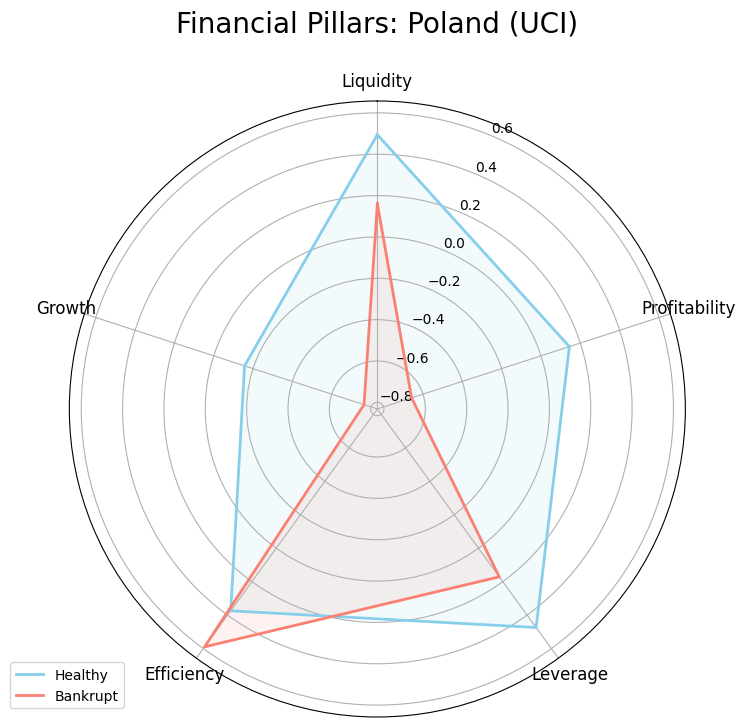

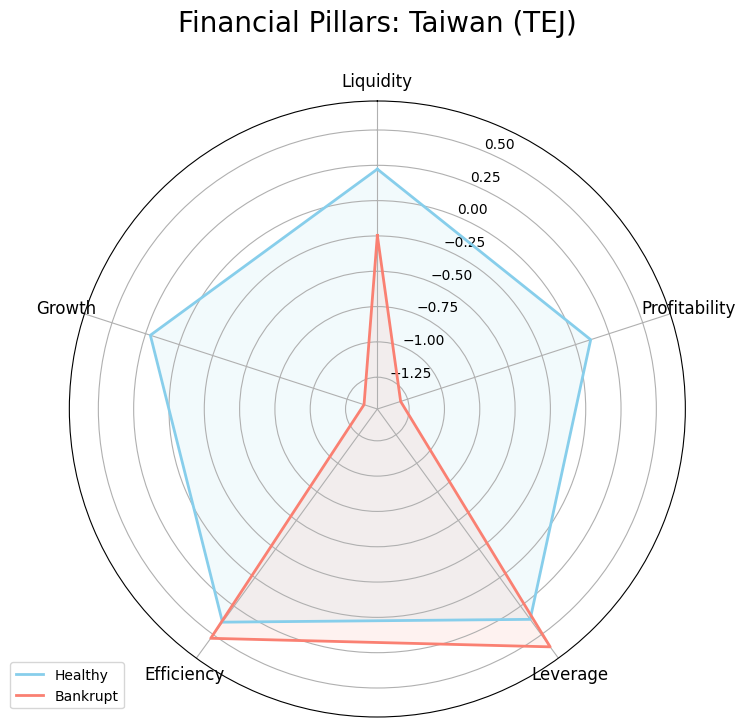

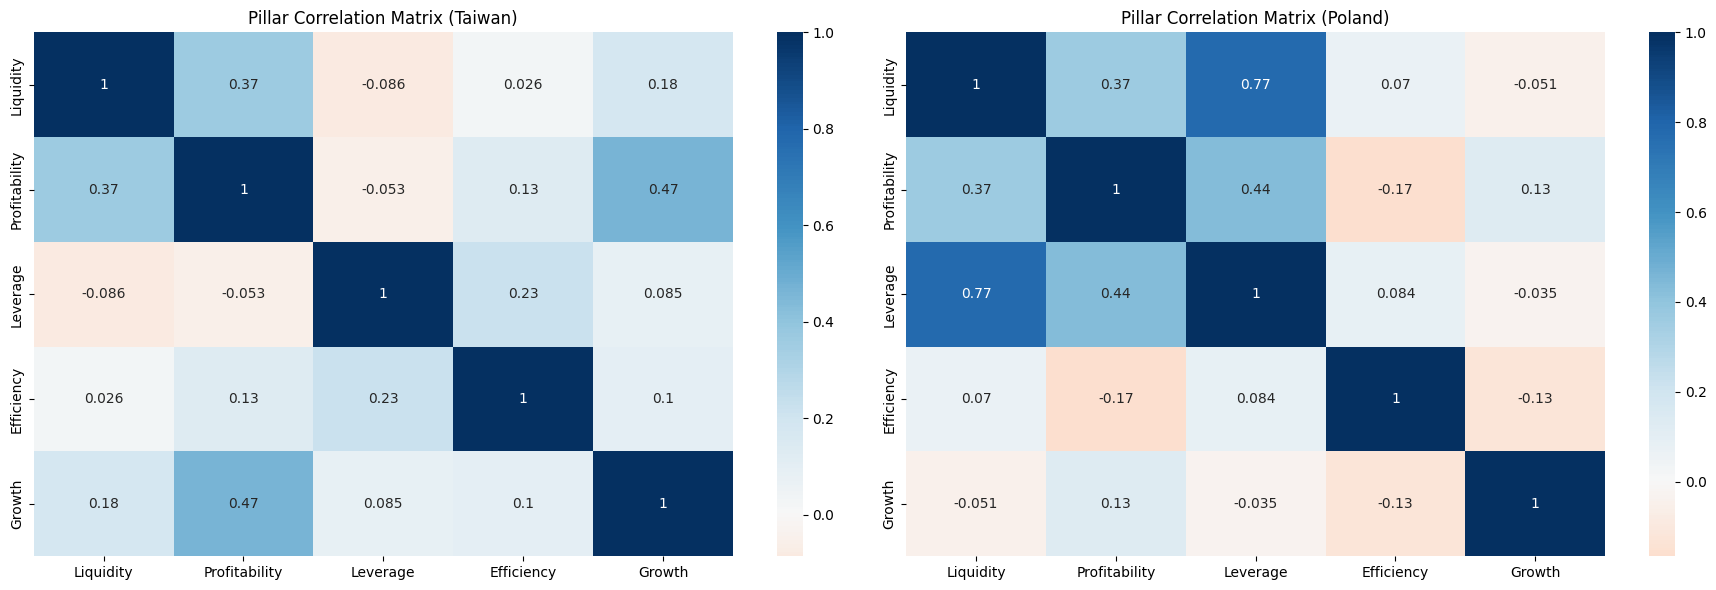

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.preprocessing import RobustScaler

# --- CLEANING STEP: Remove leading/trailing spaces from column names ---
df_taiwan.columns = df_taiwan.columns.str.strip()
df_polish.columns = df_polish.columns.str.strip()

# --- POLISH PILLAR MAPPING ---
# Dropped: A5, A37, A55, A62 (Liquidity), A15, A27 (Leverage), A20, A47, A60, A64 (Efficiency)
# Reason: structurally sparse — p99 > 100 indicating near-zero majority with extreme outliers
polish_pillars = {
    'Liquidity': ['A3', 'A4', 'A28', 'A40', 'A46', 'A50', 'A51', 'A57', 'A63'],
    'Profitability': ['A1', 'A6', 'A7', 'A11', 'A12', 'A13', 'A14', 'A18', 'A19',
                      'A22', 'A23', 'A24', 'A25', 'A31', 'A35', 'A39', 'A42', 'A45',
                      'A48', 'A49', 'A56', 'A58'],
    'Leverage': ['A2', 'A8', 'A10', 'A16', 'A17', 'A26', 'A30', 'A34', 'A38', 'A41', 'A53', 'A54', 'A59'],
    'Efficiency': ['A9', 'A32', 'A33', 'A36', 'A43', 'A44', 'A52', 'A61'],
    'Growth': ['A21']
}

# --- TAIWAN PILLAR MAPPING ---
# Dropped: Inventory/Current Liability (Liquidity)
# Dropped: Interest-bearing debt interest rate, Long-term Liability to Current Assets (Leverage)
# Dropped: Inventory Turnover Rate, Fixed Assets Turnover Frequency, Current Asset Turnover Rate,
#          Quick Asset Turnover Rate, Cash Turnover Rate, Operating Expense Rate,
#          Research and development expense rate (Efficiency)
# Dropped: Total Asset Growth Rate (Growth)
# Reason: structurally sparse — p99 > 100 indicating near-zero majority with extreme outliers
taiwan_pillars = {
    'Liquidity': ['Current Ratio', 'Quick Ratio', 'Working Capital to Total Assets',
                  'Quick Assets/Total Assets', 'Current Assets/Total Assets', 'Cash/Total Assets',
                  'Quick Assets/Current Liability', 'Cash/Current Liability',
                  'Current Liability to Assets', 'Operating Funds to Liability',
                  'Inventory/Working Capital', 'Working Capital/Equity',
                  'Cash Flow to Sales', 'Cash Flow to Total Assets', 'Cash Flow to Liability',
                  'CFO to Assets', 'Cash Flow to Equity', 'Current Liability to Current Assets',
                  'No-credit Interval', 'Cash flow rate'],

    'Profitability': ['ROA(C) before interest and depreciation before interest',
                      'ROA(A) before interest and % after tax',
                      'ROA(B) before interest and depreciation after tax',
                      'Operating Gross Margin', 'Realized Sales Gross Margin',
                      'Operating Profit Rate', 'Pre-tax net Interest Rate',
                      'After-tax net Interest Rate', 'Continuous interest rate (after tax)',
                      'Net Income to Total Assets', 'Gross Profit to Sales',
                      "Net Income to Stockholder's Equity", 'Retained Earnings to Total Assets',
                      'Operating profit/Paid-in capital', 'Net profit before tax/Paid-in capital',
                      'Total income/Total expense', 'Cash Reinvestment %',
                      'Net Value Per Share (B)', 'Net Value Per Share (A)', 'Net Value Per Share (C)',
                      'Persistent EPS in the Last Four Seasons', 'Cash Flow Per Share',
                      'Revenue Per Share (Yuan ¥)', 'Operating Profit Per Share (Yuan ¥)',
                      'Per Share Net profit before tax (Yuan ¥)',
                      'Non-industry income and expenditure/revenue', 'Tax rate (A)'],

    'Leverage': ['Interest Expense Ratio', 'Total debt/Total net worth', 'Debt ratio %',
                 'Net worth/Assets', 'Long-term fund suitability ratio (A)', 'Borrowing dependency',
                 'Contingent liabilities/Net worth', 'Liability to Equity', 'Equity to Liability',
                 'Degree of Financial Leverage (DFL)',
                 'Interest Coverage Ratio (Interest expense to EBIT)',
                 'Current Liabilities/Liability', 'Current Liability to Equity',
                 'Equity to Long-term Liability'],

    'Efficiency': ['Total Asset Turnover', 'Accounts Receivable Turnover', 'Average Collection Days',
                   'Net Worth Turnover Rate (times)', 'Revenue per person',
                   'Operating profit per person', 'Allocation rate per person',
                   'Total expense/Assets', 'Fixed Assets to Assets',
                   'Inventory and accounts receivable/Net value', 'Total assets to GNP price',
                   'Working capitcal Turnover Rate'],

    'Growth': ['Realized Sales Gross Profit Growth Rate', 'Operating Profit Growth Rate',
               'After-tax Net Profit Growth Rate', 'Regular Net Profit Growth Rate',
               'Continuous Net Profit Growth Rate', 'Net Value Growth Rate',
               'Total Asset Return Growth Rate Ratio']
}


def get_pillar_df(df, mapping, target_col):
    all_mapped_cols = [col for cols in mapping.values() for col in cols]
    available_cols = [col for col in all_mapped_cols if col in df.columns]

    # Step 1: Winsorize at 1st/99th percentile
    df_clipped = df[available_cols].copy()
    for col in available_cols:
        lower = df_clipped[col].quantile(0.01)
        upper = df_clipped[col].quantile(0.99)
        df_clipped[col] = df_clipped[col].clip(lower, upper)

    # Step 2: RobustScaler
    scaler = RobustScaler()
    scaled_data = scaler.fit_transform(df_clipped.fillna(0))
    df_scaled = pd.DataFrame(scaled_data, columns=available_cols)

    # Step 3: Post-scaling safety clip — catches any remaining extreme values
    df_scaled = df_scaled.clip(-10, 10)

    # Step 4: Average within each pillar
    pillar_df = pd.DataFrame()
    for pillar, cols in mapping.items():
        valid_cols = [c for c in cols if c in df_scaled.columns]
        if valid_cols:
            pillar_df[pillar] = df_scaled[valid_cols].mean(axis=1)

    pillar_df['Target'] = df[target_col].values
    return pillar_df


# Generate aggregated data
df_pl_agg = get_pillar_df(df_polish, polish_pillars, 'class')
df_tw_agg = get_pillar_df(df_taiwan, taiwan_pillars, 'Bankrupt?')


# --- VISUALIZATION: Radar Plot ---
def plot_radar(df, title):
    categories = list(df.columns[:-1])
    N = len(categories)

    bankrupt = df[df['Target'] == 1][categories].mean().tolist()
    healthy = df[df['Target'] == 0][categories].mean().tolist()

    bankrupt += bankrupt[:1]
    healthy += healthy[:1]
    angles = [n / float(N) * 2 * np.pi for n in range(N)]
    angles += angles[:1]

    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

    ax.plot(angles, healthy, linewidth=2, linestyle='solid', label='Healthy', color='skyblue')
    ax.fill(angles, healthy, 'skyblue', alpha=0.1)

    ax.plot(angles, bankrupt, linewidth=2, linestyle='solid', label='Bankrupt', color='salmon')
    ax.fill(angles, bankrupt, 'salmon', alpha=0.1)

    ax.set_theta_offset(np.pi / 2)
    ax.set_theta_direction(-1)
    plt.xticks(angles[:-1], categories, size=12)
    plt.title(title, size=20, y=1.1)
    plt.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))
    plt.show()


plot_radar(df_pl_agg, "Financial Pillars: Poland (UCI)")
plot_radar(df_tw_agg, "Financial Pillars: Taiwan (TEJ)")


# --- VISUALIZATION: Heatmap (both datasets side by side) ---
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

sns.heatmap(df_tw_agg.drop(columns='Target').corr(), annot=True, cmap='RdBu', center=0, ax=axes[0])
axes[0].set_title("Pillar Correlation Matrix (Taiwan)")

sns.heatmap(df_pl_agg.drop(columns='Target').corr(), annot=True, cmap='RdBu', center=0, ax=axes[1])
axes[1].set_title("Pillar Correlation Matrix (Poland)")

plt.tight_layout()
plt.show()

In [3]:
# Check outlier severity for both datasets

# Taiwan
taiwan_stats = df_taiwan.describe().T[['min', '25%', '75%', 'max']]
taiwan_stats['IQR'] = taiwan_stats['75%'] - taiwan_stats['25%']
taiwan_stats['lower_fence'] = taiwan_stats['25%'] - 3 * taiwan_stats['IQR']
taiwan_stats['upper_fence'] = taiwan_stats['75%'] + 3 * taiwan_stats['IQR']
taiwan_stats['outlier_count'] = ((df_taiwan < taiwan_stats['lower_fence']) | 
                                  (df_taiwan > taiwan_stats['upper_fence'])).sum()
taiwan_stats['outlier_%'] = (taiwan_stats['outlier_count'] / len(df_taiwan) * 100).round(2)

print("=== TAIWAN OUTLIER SUMMARY ===")
print(taiwan_stats[['min', 'max', 'IQR', 'outlier_count', 'outlier_%']].sort_values('outlier_%', ascending=False).head(20))

# Polish
polish_cols = [col for col in df_polish.columns if col not in ['class', 'year']]
polish_stats = df_polish[polish_cols].describe().T[['min', '25%', '75%', 'max']]
polish_stats['IQR'] = polish_stats['75%'] - polish_stats['25%']
polish_stats['lower_fence'] = polish_stats['25%'] - 3 * polish_stats['IQR']
polish_stats['upper_fence'] = polish_stats['75%'] + 3 * polish_stats['IQR']
polish_stats['outlier_count'] = ((df_polish[polish_cols] < polish_stats['lower_fence']) | 
                                  (df_polish[polish_cols] > polish_stats['upper_fence'])).sum()
polish_stats['outlier_%'] = (polish_stats['outlier_count'] / len(df_polish) * 100).round(2)

print("\n=== POLISH OUTLIER SUMMARY ===")
print(polish_stats[['min', 'max', 'IQR', 'outlier_count', 'outlier_%']].sort_values('outlier_%', ascending=False).head(20))

=== TAIWAN OUTLIER SUMMARY ===
                                                    min           max  \
Fixed Assets Turnover Frequency                     0.0  9.990000e+09   
Current Asset Turnover Rate                         0.0  1.000000e+10   
Degree of Financial Leverage (DFL)                  0.0  1.000000e+00   
Interest Coverage Ratio (Interest expense to EBIT)  0.0  1.000000e+00   
Interest Expense Ratio                              0.0  1.000000e+00   
Cash Flow to Liability                              0.0  1.000000e+00   
Regular Net Profit Growth Rate                      0.0  1.000000e+00   
After-tax Net Profit Growth Rate                    0.0  1.000000e+00   
Continuous Net Profit Growth Rate                   0.0  1.000000e+00   
No-credit Interval                                  0.0  1.000000e+00   
Operating Profit Growth Rate                        0.0  1.000000e+00   
Non-industry income and expenditure/revenue         0.0  1.000000e+00   
Long-term fund suita

In [4]:
# Check if Taiwan columns are being read as numeric
print("=== TAIWAN DTYPES (non-numeric columns) ===")
print(df_taiwan.dtypes[df_taiwan.dtypes == 'object'])

# Check what the pillar scores actually look like after aggregation
print("\n=== TAIWAN PILLAR SCORE RANGES ===")
print(df_tw_agg.describe())

print("\n=== POLISH PILLAR SCORE RANGES ===")
print(df_pl_agg.describe())

# Find which individual features inside each pillar are still extreme AFTER winsorizing
def diagnose_pillar_explosions(df, mapping, percentile=0.99):
    print("Features with 99th percentile > 100 (still extreme after winsorizing):\n")
    for pillar, cols in mapping.items():
        valid_cols = [c for c in cols if c in df.columns]
        for col in valid_cols:
            p99 = df[col].quantile(percentile)
            p01 = df[col].quantile(1 - percentile)
            if abs(p99) > 100 or abs(p01) > 100:
                print(f"  [{pillar}] {col}: p1={p01:.2f}, p99={p99:.2f}")

print("=== TAIWAN ===")
diagnose_pillar_explosions(df_taiwan, taiwan_pillars)

print("\n=== POLISH ===")
diagnose_pillar_explosions(df_polish, polish_pillars)

=== TAIWAN DTYPES (non-numeric columns) ===
Series([], dtype: object)

=== TAIWAN PILLAR SCORE RANGES ===
         Liquidity  Profitability     Leverage   Efficiency       Growth  \
count  6819.000000    6819.000000  6819.000000  6819.000000  6819.000000   
mean      0.207860       0.067252     0.373286     0.394789     0.163109   
std       0.681631       0.889030     0.649253     0.553553     1.750172   
min      -2.028197      -3.652473    -2.077514    -0.758749    -7.239152   
25%      -0.160593      -0.308554     0.002037     0.066850    -0.420067   
50%       0.075939       0.088425     0.213052     0.226391     0.061579   
75%       0.420246       0.536407     0.636156     0.514811     0.701176   
max       4.071327       3.265106     3.340354     4.278385     9.413051   

            Target  
count  6819.000000  
mean      0.032263  
std       0.176710  
min       0.000000  
25%       0.000000  
50%       0.000000  
75%       0.000000  
max       1.000000  

=== POLISH PILLAR S

## Data preprocesssing

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.impute import SimpleImputer
from imblearn.over_sampling import SMOTE
import pandas as pd

# --- TAIWAN DATASET PREPROCESSING ---
X_tw = df_taiwan.drop(columns=['Bankrupt?'])
y_tw = df_taiwan['Bankrupt?'].astype(int) # Ensure binary integer

# --- POLISH DATASET PREPROCESSING ---
# Explicitly drop the year and class from features; use class as target
X_pl = df_polish.drop(columns=['class', 'year'])
y_pl = df_polish['class'].astype(int) # This fixes the [1,2,3,4,5] error

# Safety: Convert Polish features to numeric (handles '?' or 'NA' strings)
X_pl = X_pl.apply(pd.to_numeric, errors='coerce')

# --- TRAIN-TEST SPLIT ---
X_tw_train, X_tw_test, y_tw_train, y_tw_test = train_test_split(
    X_tw, y_tw, test_size=0.2, stratify=y_tw, random_state=42
)
X_pl_train, X_pl_test, y_pl_train, y_pl_test = train_test_split(
    X_pl, y_pl, test_size=0.2, stratify=y_pl, random_state=42
)

# --- IMPUTATION (Handling missing values) ---
imputer_tw = SimpleImputer(strategy='median')
X_tw_train_imp = imputer_tw.fit_transform(X_tw_train)
X_tw_test_imp = imputer_tw.transform(X_tw_test)

imputer_pl = SimpleImputer(strategy='median')
X_pl_train_imp = imputer_pl.fit_transform(X_pl_train)
X_pl_test_imp = imputer_pl.transform(X_pl_test)

# --- SCALING ---
scaler_tw = RobustScaler()
X_tw_train_sc = scaler_tw.fit_transform(X_tw_train_imp)
X_tw_test_sc = scaler_tw.transform(X_tw_test_imp)

scaler_pl = RobustScaler()
X_pl_train_sc = scaler_pl.fit_transform(X_pl_train_imp)
X_pl_test_sc = scaler_pl.transform(X_pl_test_imp)

# --- SMOTE (Oversampling the minority/Bankrupt class) ---
smote = SMOTE(random_state=42)
X_tw_train_res, y_tw_train_res = smote.fit_resample(X_tw_train_sc, y_tw_train)
X_pl_train_res, y_pl_train_res = smote.fit_resample(X_pl_train_sc, y_pl_train)

print("Preprocessing complete. Targets are now binary.")

Preprocessing complete. Targets are now binary.


In [6]:
print(y_pl_test.unique())
print(y_pl_test.value_counts())

[0 1]
class
0    8263
1     418
Name: count, dtype: int64


## Model Architecture , Training and Evaluation

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from imblearn.over_sampling import SMOTE

# --- TAIWAN PILLAR SPLIT ---
X_tw_pillars = df_tw_agg.drop(columns='Target')
y_tw_pillars = df_tw_agg['Target']

X_tw_p_train, X_tw_p_test, y_tw_p_train, y_tw_p_test = train_test_split(
    X_tw_pillars, y_tw_pillars, test_size=0.2, random_state=42, stratify=y_tw_pillars
)

sm = SMOTE(random_state=42)
X_tw_p_train_res, y_tw_p_train_res = sm.fit_resample(X_tw_p_train, y_tw_p_train)

# No scaling needed — pillars are already RobustScaled from get_pillar_df
# But we still scale test set for consistency
sc = RobustScaler()
X_tw_p_train_res = sc.fit_transform(X_tw_p_train_res)
X_tw_p_test_sc = sc.transform(X_tw_p_test)

# --- POLISH PILLAR SPLIT ---
X_pl_pillars = df_pl_agg.drop(columns='Target')
y_pl_pillars = df_pl_agg['Target']

X_pl_p_train, X_pl_p_test, y_pl_p_train, y_pl_p_test = train_test_split(
    X_pl_pillars, y_pl_pillars, test_size=0.2, random_state=42, stratify=y_pl_pillars
)

X_pl_p_train_res, y_pl_p_train_res = sm.fit_resample(X_pl_p_train, y_pl_p_train)

sc2 = RobustScaler()
X_pl_p_train_res = sc2.fit_transform(X_pl_p_train_res)
X_pl_p_test_sc = sc2.transform(X_pl_p_test)

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score
from xgboost import XGBClassifier
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings('ignore', category=ConvergenceWarning)

# --- FULL FEATURE MODEL DICTIONARIES ---
models_tw_full = {
    "Logistic Regression": LogisticRegression(solver='saga', max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42),
    "Gradient Boosting": XGBClassifier(n_estimators=100, eval_metric='logloss', random_state=42, n_jobs=-1)
}
models_pl_full = {
    "Logistic Regression": LogisticRegression(solver='saga', max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42),
    "Gradient Boosting": XGBClassifier(n_estimators=100, eval_metric='logloss', random_state=42, n_jobs=-1)
}

# --- PILLAR MODEL DICTIONARIES ---
models_tw_pillars = {
    "Logistic Regression": LogisticRegression(solver='saga', max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42),
    "Gradient Boosting": XGBClassifier(n_estimators=100, eval_metric='logloss', random_state=42, n_jobs=-1)
}
models_pl_pillars = {
    "Logistic Regression": LogisticRegression(solver='saga', max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42),
    "Gradient Boosting": XGBClassifier(n_estimators=100, eval_metric='logloss', random_state=42, n_jobs=-1)
}

# --- Training Loop: Taiwan Full Features ---
results_tw = {}
for name, model in models_tw_full.items():
    print(f"Training Taiwan Full: {name}...")
    model.fit(X_tw_train_res, y_tw_train_res)
    y_pred = model.predict(X_tw_test_sc)
    y_prob = model.predict_proba(X_tw_test_sc)[:, 1]
    results_tw[name] = {
        "classification_report": classification_report(y_tw_test, y_pred),
        "roc_auc": roc_auc_score(y_tw_test, y_prob)
    }
    print(f"  Done. ROC-AUC: {results_tw[name]['roc_auc']:.4f}")

# --- Training Loop: Poland Full Features ---
results_pl = {}
for name, model in models_pl_full.items():
    print(f"Training Poland Full: {name}...")
    model.fit(X_pl_train_res, y_pl_train_res)
    y_pred = model.predict(X_pl_test_sc)
    y_prob = model.predict_proba(X_pl_test_sc)[:, 1]
    results_pl[name] = {
        "classification_report": classification_report(y_pl_test, y_pred),
        "roc_auc": roc_auc_score(y_pl_test, y_prob)
    }
    print(f"  Done. ROC-AUC: {results_pl[name]['roc_auc']:.4f}")

# --- Training Loop: Taiwan Pillars ---
results_tw_pillars = {}
for name, model in models_tw_pillars.items():
    print(f"Training Taiwan Pillars: {name}...")
    model.fit(X_tw_p_train_res, y_tw_p_train_res)
    y_pred = model.predict(X_tw_p_test_sc)
    y_prob = model.predict_proba(X_tw_p_test_sc)[:, 1]
    results_tw_pillars[name] = {
        "classification_report": classification_report(y_tw_p_test, y_pred),
        "roc_auc": roc_auc_score(y_tw_p_test, y_prob)
    }
    print(f"  Done. ROC-AUC: {results_tw_pillars[name]['roc_auc']:.4f}")

# --- Training Loop: Poland Pillars ---
results_pl_pillars = {}
for name, model in models_pl_pillars.items():
    print(f"Training Poland Pillars: {name}...")
    model.fit(X_pl_p_train_res, y_pl_p_train_res)
    y_pred = model.predict(X_pl_p_test_sc)
    y_prob = model.predict_proba(X_pl_p_test_sc)[:, 1]
    results_pl_pillars[name] = {
        "classification_report": classification_report(y_pl_p_test, y_pred),
        "roc_auc": roc_auc_score(y_pl_p_test, y_prob)
    }
    print(f"  Done. ROC-AUC: {results_pl_pillars[name]['roc_auc']:.4f}")

# --- Display All Results ---
print("\n========== TAIWAN FULL FEATURE RESULTS ==========")
for name, metrics in results_tw.items():
    print(f"\n--- Taiwan Full: {name} ---")
    print(f"ROC-AUC: {metrics['roc_auc']:.4f}")
    print(metrics['classification_report'])

print("\n========== POLAND FULL FEATURE RESULTS ==========")
for name, metrics in results_pl.items():
    print(f"\n--- Poland Full: {name} ---")
    print(f"ROC-AUC: {metrics['roc_auc']:.4f}")
    print(metrics['classification_report'])

print("\n========== TAIWAN PILLAR RESULTS ==========")
for name, metrics in results_tw_pillars.items():
    print(f"\n--- Taiwan Pillars: {name} ---")
    print(f"ROC-AUC: {metrics['roc_auc']:.4f}")
    print(metrics['classification_report'])

print("\n========== POLAND PILLAR RESULTS ==========")
for name, metrics in results_pl_pillars.items():
    print(f"\n--- Poland Pillars: {name} ---")
    print(f"ROC-AUC: {metrics['roc_auc']:.4f}")
    print(metrics['classification_report'])

Training Taiwan Full: Logistic Regression...
  Done. ROC-AUC: 0.6026
Training Taiwan Full: Random Forest...
  Done. ROC-AUC: 0.9519
Training Taiwan Full: Gradient Boosting...
  Done. ROC-AUC: 0.9503
Training Poland Full: Logistic Regression...
  Done. ROC-AUC: 0.6436
Training Poland Full: Random Forest...
  Done. ROC-AUC: 0.9283
Training Poland Full: Gradient Boosting...
  Done. ROC-AUC: 0.9643
Training Taiwan Pillars: Logistic Regression...
  Done. ROC-AUC: 0.9040
Training Taiwan Pillars: Random Forest...
  Done. ROC-AUC: 0.9071
Training Taiwan Pillars: Gradient Boosting...
  Done. ROC-AUC: 0.8657
Training Poland Pillars: Logistic Regression...
  Done. ROC-AUC: 0.7188
Training Poland Pillars: Random Forest...
  Done. ROC-AUC: 0.6712
Training Poland Pillars: Gradient Boosting...
  Done. ROC-AUC: 0.6826

========== TAIWAN FULL FEATURE RESULTS ==========

--- Taiwan Full: Logistic Regression ---
ROC-AUC: 0.6026
              precision    recall  f1-score   support

           0       0.9

## SHAP explainability

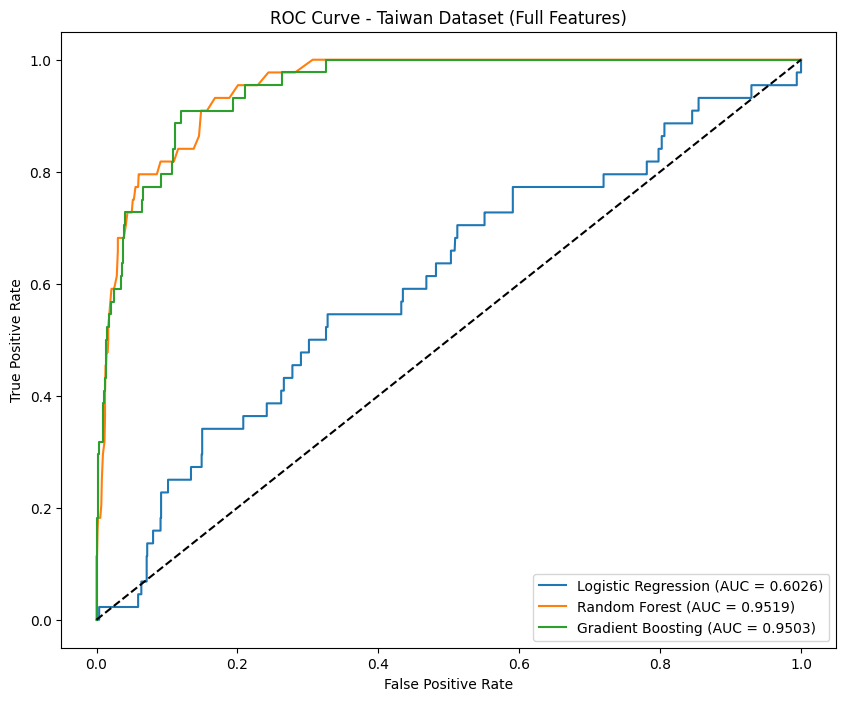

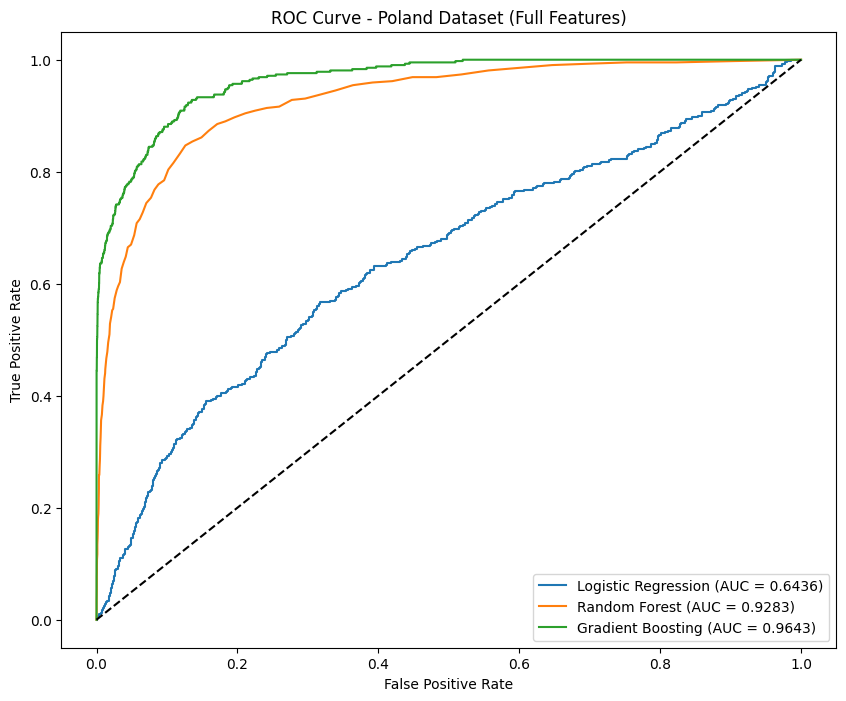

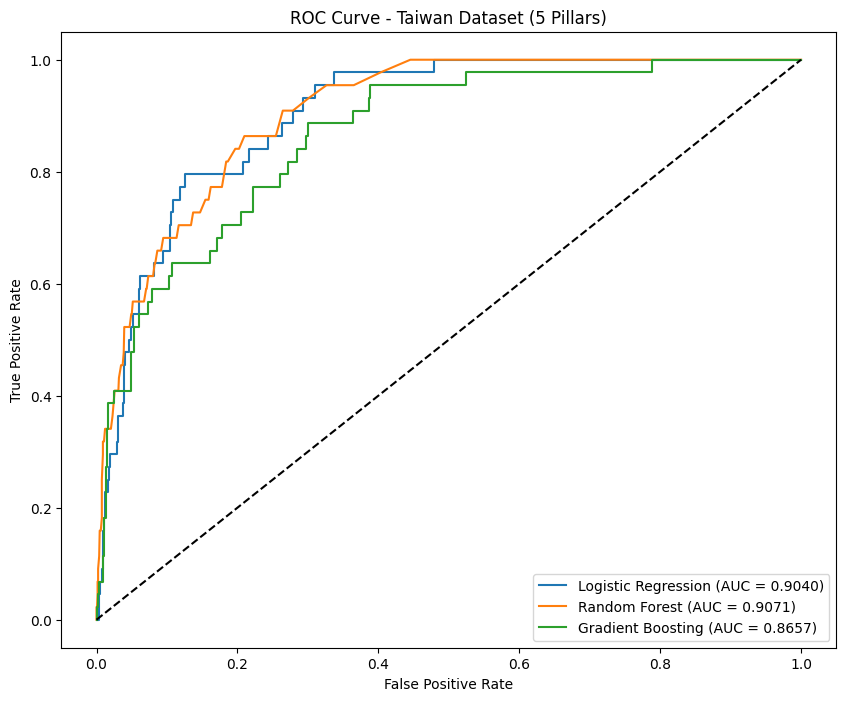

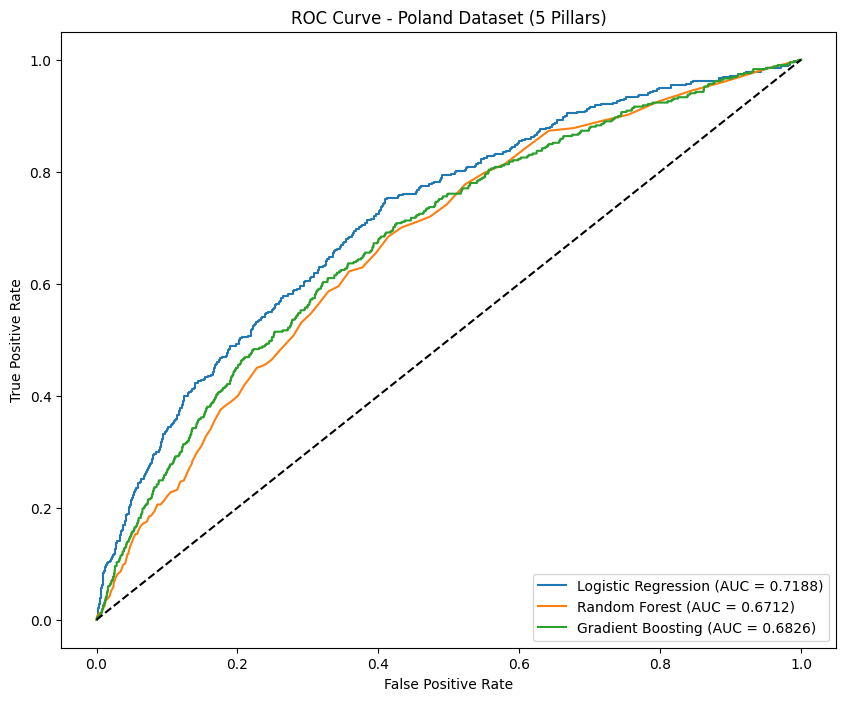

Generating SHAP for Taiwan (Full Features)...


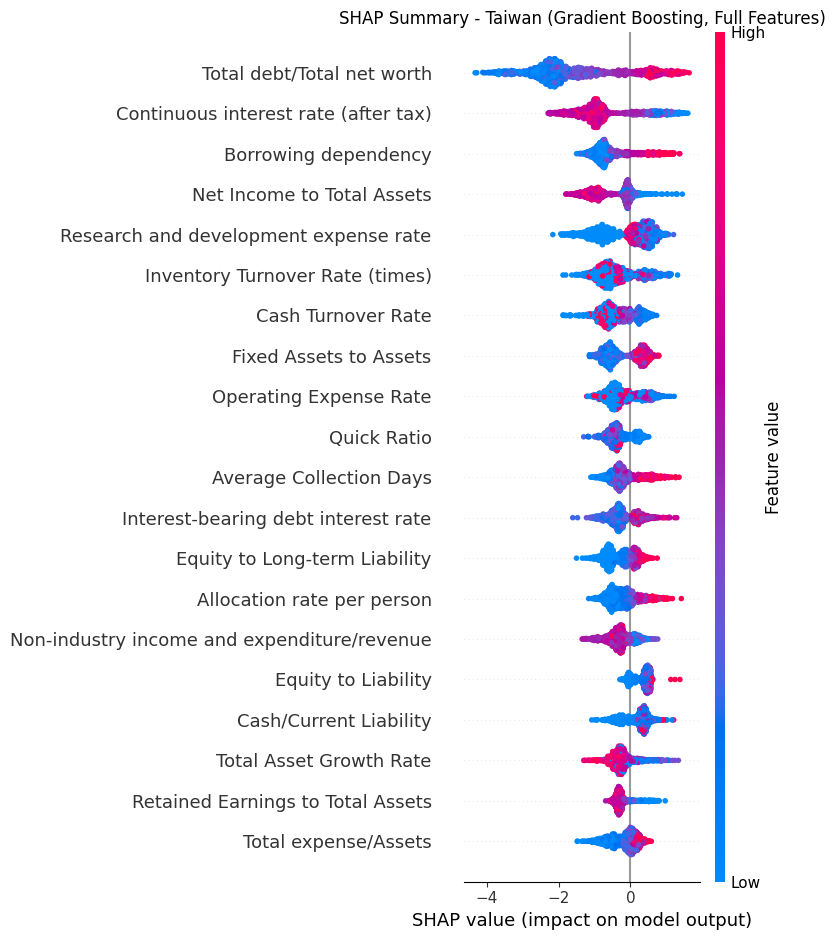

Generating SHAP for Poland (Full Features)...


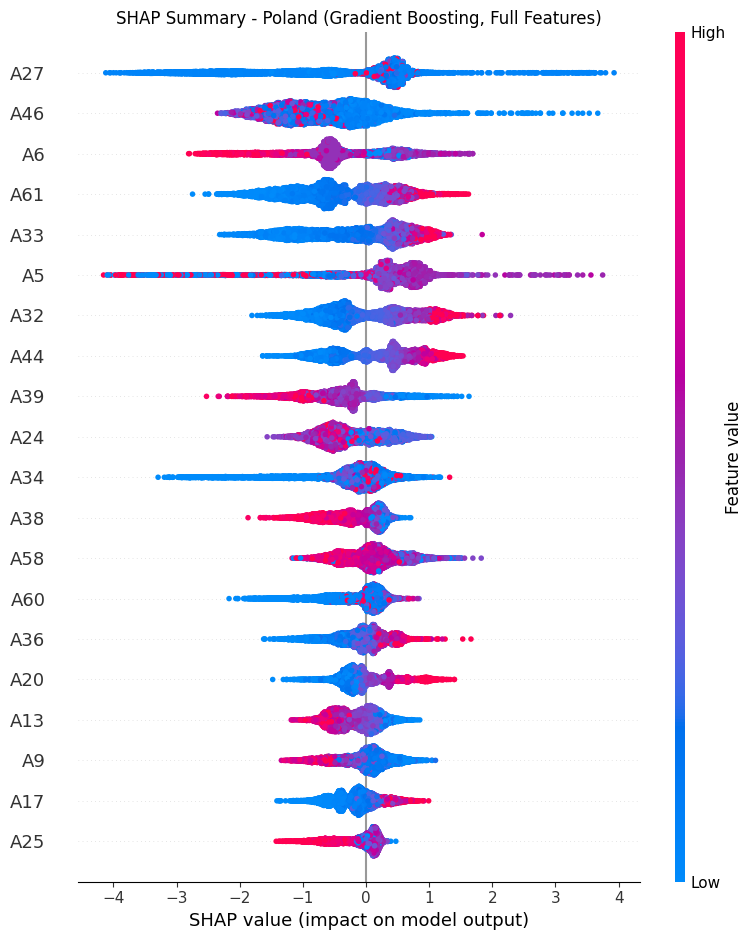

Generating SHAP for Taiwan (5 Pillars)...


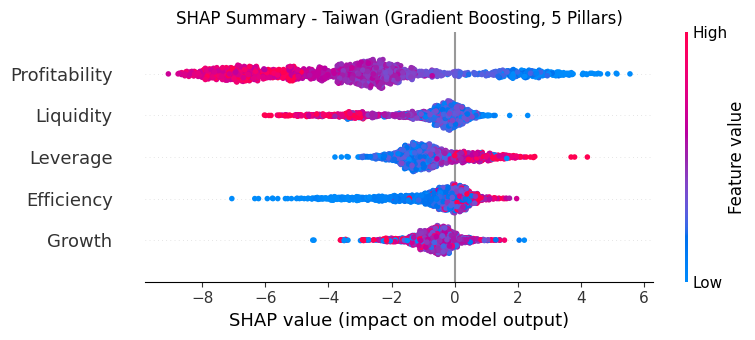

Generating SHAP for Poland (5 Pillars)...


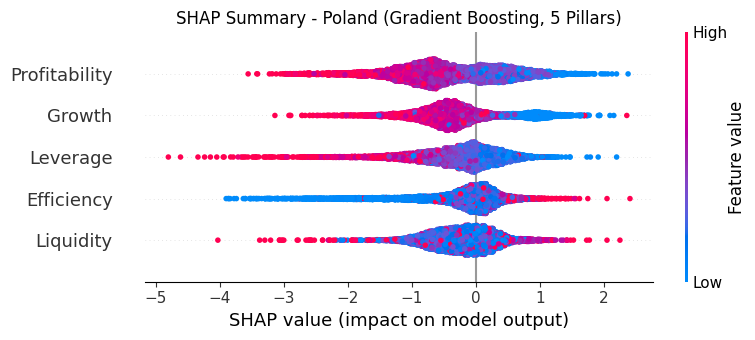

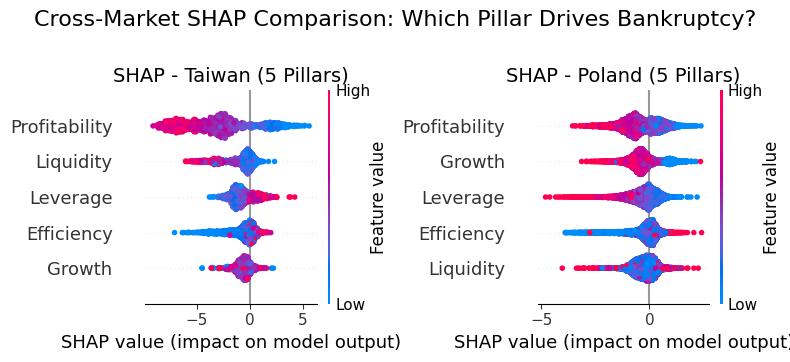

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve
import shap

# ================================================================
# ROC CURVES — FULL FEATURES
# ================================================================

# --- ROC Curve: Taiwan Full Features ---
plt.figure(figsize=(10, 8))
for name, metrics in results_tw.items():
    model = models_tw_full[name]
    y_prob = model.predict_proba(X_tw_test_sc)[:, 1]
    fpr, tpr, _ = roc_curve(y_tw_test, y_prob)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {metrics["roc_auc"]:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.title('ROC Curve - Taiwan Dataset (Full Features)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.show()

# --- ROC Curve: Poland Full Features ---
plt.figure(figsize=(10, 8))
for name, metrics in results_pl.items():
    model = models_pl_full[name]
    y_prob = model.predict_proba(X_pl_test_sc)[:, 1]
    fpr, tpr, _ = roc_curve(y_pl_test, y_prob)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {metrics["roc_auc"]:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.title('ROC Curve - Poland Dataset (Full Features)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.show()

# ================================================================
# ROC CURVES — 5 PILLARS
# ================================================================

# --- ROC Curve: Taiwan Pillars ---
plt.figure(figsize=(10, 8))
for name, metrics in results_tw_pillars.items():
    model = models_tw_pillars[name]
    y_prob = model.predict_proba(X_tw_p_test_sc)[:, 1]
    fpr, tpr, _ = roc_curve(y_tw_p_test, y_prob)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {metrics["roc_auc"]:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.title('ROC Curve - Taiwan Dataset (5 Pillars)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.show()

# --- ROC Curve: Poland Pillars ---
plt.figure(figsize=(10, 8))
for name, metrics in results_pl_pillars.items():
    model = models_pl_pillars[name]
    y_prob = model.predict_proba(X_pl_p_test_sc)[:, 1]
    fpr, tpr, _ = roc_curve(y_pl_p_test, y_prob)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {metrics["roc_auc"]:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.title('ROC Curve - Poland Dataset (5 Pillars)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.show()

# ================================================================
# SHAP — FULL FEATURES (Gradient Boosting only)
# ================================================================

# --- SHAP: Taiwan Full Features ---
print("Generating SHAP for Taiwan (Full Features)...")
best_tw_full = models_tw_full['Gradient Boosting']
explainer_tw_full = shap.TreeExplainer(best_tw_full)
shap_values_tw_full = explainer_tw_full.shap_values(X_tw_test_sc)
plt.figure(figsize=(12, 8))
plt.title('SHAP Summary - Taiwan (Gradient Boosting, Full Features)')
shap.summary_plot(shap_values_tw_full, X_tw_test_sc, 
                  feature_names=list(X_tw.columns), show=False)
plt.tight_layout()
plt.show()

# --- SHAP: Poland Full Features ---
print("Generating SHAP for Poland (Full Features)...")
best_pl_full = models_pl_full['Gradient Boosting']
explainer_pl_full = shap.TreeExplainer(best_pl_full)
shap_values_pl_full = explainer_pl_full.shap_values(X_pl_test_sc)
plt.figure(figsize=(12, 8))
plt.title('SHAP Summary - Poland (Gradient Boosting, Full Features)')
shap.summary_plot(shap_values_pl_full, X_pl_test_sc, 
                  feature_names=list(X_pl.columns), show=False)
plt.tight_layout()
plt.show()

# ================================================================
# SHAP — 5 PILLARS (Gradient Boosting only)
# ================================================================

pillar_names = ['Liquidity', 'Profitability', 'Leverage', 'Efficiency', 'Growth']

# --- SHAP: Taiwan Pillars ---
print("Generating SHAP for Taiwan (5 Pillars)...")
best_tw_pillars = models_tw_pillars['Gradient Boosting']
explainer_tw_p = shap.TreeExplainer(best_tw_pillars)
shap_values_tw_p = explainer_tw_p.shap_values(X_tw_p_test_sc)
plt.figure(figsize=(10, 6))
plt.title('SHAP Summary - Taiwan (Gradient Boosting, 5 Pillars)')
shap.summary_plot(shap_values_tw_p, X_tw_p_test_sc, 
                  feature_names=pillar_names, show=False)
plt.tight_layout()
plt.show()

# --- SHAP: Poland Pillars ---
print("Generating SHAP for Poland (5 Pillars)...")
best_pl_pillars = models_pl_pillars['Gradient Boosting']
explainer_pl_p = shap.TreeExplainer(best_pl_pillars)
shap_values_pl_p = explainer_pl_p.shap_values(X_pl_p_test_sc)
plt.figure(figsize=(10, 6))
plt.title('SHAP Summary - Poland (Gradient Boosting, 5 Pillars)')
shap.summary_plot(shap_values_pl_p, X_pl_p_test_sc, 
                  feature_names=pillar_names, show=False)
plt.tight_layout()
plt.show()

# ================================================================
# SIDE-BY-SIDE SHAP COMPARISON — PILLARS ONLY (cross-dataset)
# ================================================================

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

plt.sca(axes[0])
shap.summary_plot(shap_values_tw_p, X_tw_p_test_sc,
                  feature_names=pillar_names, show=False)
axes[0].set_title('SHAP - Taiwan (5 Pillars)', size=14)

plt.sca(axes[1])
shap.summary_plot(shap_values_pl_p, X_pl_p_test_sc,
                  feature_names=pillar_names, show=False)
axes[1].set_title('SHAP - Poland (5 Pillars)', size=14)

plt.suptitle('Cross-Market SHAP Comparison: Which Pillar Drives Bankruptcy?', 
             size=16, y=1.02)
plt.tight_layout()
plt.show()

## Longitudinal Analysis: 5-Year Bankruptcy Trajectory (Polish Dataset)

The Polish UCI dataset contains a unique structural feature: financial data is recorded across **5 forecasting horizons**, where Year 1 = 5 years before the bankruptcy outcome, and Year 5 = 1 year before. By computing pillar scores at each horizon separately for bankrupt vs. healthy companies, we can answer the core EWS question: **which financial pillar deteriorates first, and how early can distress be detected?**

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd
from sklearn.preprocessing import RobustScaler

# ================================================================
# LONGITUDINAL 5-YEAR TRAJECTORY ANALYSIS
# Polish dataset only — exploits the unique yearly snapshot structure
# Year 1 = 5 years before outcome | Year 5 = 1 year before outcome
# ================================================================

pillars = ['Liquidity', 'Profitability', 'Leverage', 'Efficiency', 'Growth']

def get_pillar_scores_for_year(df_year, mapping):
    """
    Compute pillar scores for a single year slice of the Polish dataset.
    Applies the same winsorize -> RobustScale -> clip -> average pipeline
    used in the main EDA cell.
    """
    all_mapped_cols = [col for cols in mapping.values() for col in cols]
    available_cols = [col for col in all_mapped_cols if col in df_year.columns]

    df_clipped = df_year[available_cols].copy()
    for col in available_cols:
        lower = df_clipped[col].quantile(0.01)
        upper = df_clipped[col].quantile(0.99)
        df_clipped[col] = df_clipped[col].clip(lower, upper)

    scaler = RobustScaler()
    scaled_data = scaler.fit_transform(df_clipped.fillna(0))
    df_scaled = pd.DataFrame(scaled_data, columns=available_cols)
    df_scaled = df_scaled.clip(-10, 10)

    pillar_df = pd.DataFrame()
    for pillar, cols in mapping.items():
        valid_cols = [c for c in cols if c in df_scaled.columns]
        if valid_cols:
            pillar_df[pillar] = df_scaled[valid_cols].mean(axis=1)

    pillar_df['Target'] = df_year['class'].values
    return pillar_df

# ================================================================
# STEP 1: Compute mean pillar scores per year per class
# ================================================================
trajectory_bankrupt = {p: [] for p in pillars}
trajectory_healthy  = {p: [] for p in pillars}
year_labels = []
sample_counts = []

for yr in range(1, 6):
    df_yr = df_polish[df_polish['year'] == yr].copy()
    n_bankrupt = (df_yr['class'] == 1).sum()
    n_healthy  = (df_yr['class'] == 0).sum()
    sample_counts.append((yr, n_bankrupt, n_healthy))

    pillar_yr = get_pillar_scores_for_year(df_yr, polish_pillars)

    bankrupt_means = pillar_yr[pillar_yr['Target'] == 1][pillars].mean()
    healthy_means  = pillar_yr[pillar_yr['Target'] == 0][pillars].mean()

    for p in pillars:
        trajectory_bankrupt[p].append(bankrupt_means[p])
        trajectory_healthy[p].append(healthy_means[p])

    # Year 1 = 5 years before, Year 5 = 1 year before
    years_before = 6 - yr
    year_labels.append(f'T-{years_before}')
    print(f"Year {yr} (T-{years_before}): {n_bankrupt} bankrupt | {n_healthy} healthy")

x = np.arange(1, 6)  # 5 time points

# ================================================================
# STEP 2: Individual pillar trajectory plots
# ================================================================
colors = {
    'Liquidity':    '#2196F3',
    'Profitability':'#4CAF50',
    'Leverage':     '#F44336',
    'Efficiency':   '#FF9800',
    'Growth':       '#9C27B0'
}

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for idx, pillar in enumerate(pillars):
    ax = axes[idx]
    b_vals = trajectory_bankrupt[pillar]
    h_vals = trajectory_healthy[pillar]

    ax.plot(x, h_vals, 'o-', color=colors[pillar], linewidth=2.5,
            markersize=8, label='Healthy', alpha=0.9)
    ax.plot(x, b_vals, 's--', color=colors[pillar], linewidth=2.5,
            markersize=8, label='Bankrupt', alpha=0.6)

    ax.fill_between(x, b_vals, h_vals,
                    alpha=0.08, color=colors[pillar])

    ax.set_xticks(x)
    ax.set_xticklabels(year_labels, fontsize=11)
    ax.set_title(f'{pillar} Score', fontsize=14, fontweight='bold')
    ax.set_xlabel('Years Before Bankruptcy Outcome', fontsize=10)
    ax.set_ylabel('Mean Pillar Score (Robust Scaled)', fontsize=10)
    ax.axhline(0, color='gray', linewidth=0.8, linestyle=':')
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3)

# Hide the unused 6th subplot
axes[5].set_visible(False)

fig.suptitle('5-Year Financial Pillar Trajectory: Bankrupt vs Healthy Companies\n(Polish UCI Dataset)',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# ================================================================
# STEP 3: Combined overlay — all pillars, bankrupt companies only
# Shows which pillar deteriorates FIRST
# ================================================================
fig, ax = plt.subplots(figsize=(12, 7))

for pillar in pillars:
    b_vals = trajectory_bankrupt[pillar]
    ax.plot(x, b_vals, 'o-', color=colors[pillar],
            linewidth=2.5, markersize=8, label=pillar)

ax.set_xticks(x)
ax.set_xticklabels(year_labels, fontsize=12)
ax.set_title('Pillar Deterioration Trajectory — Bankrupt Companies Only\nWhich pillar fails first?',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Years Before Bankruptcy Outcome', fontsize=12)
ax.set_ylabel('Mean Pillar Score (Robust Scaled)', fontsize=12)
ax.axhline(0, color='gray', linewidth=1, linestyle='--', label='Zero baseline')
ax.legend(fontsize=11, loc='upper right')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ================================================================
# STEP 4: Gap analysis — how much does each pillar diverge per year?
# Gap = Healthy mean - Bankrupt mean (larger = more separable)
# ================================================================
fig, ax = plt.subplots(figsize=(12, 7))

for pillar in pillars:
    gaps = [h - b for h, b in zip(trajectory_healthy[pillar], trajectory_bankrupt[pillar])]
    ax.plot(x, gaps, 'o-', color=colors[pillar],
            linewidth=2.5, markersize=8, label=pillar)

ax.set_xticks(x)
ax.set_xticklabels(year_labels, fontsize=12)
ax.set_title('Separation Gap Between Healthy and Bankrupt Companies Per Year\n(Larger gap = stronger early warning signal)',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Years Before Bankruptcy Outcome', fontsize=12)
ax.set_ylabel('Gap (Healthy Mean − Bankrupt Mean)', fontsize=12)
ax.axhline(0, color='gray', linewidth=1, linestyle='--')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ================================================================
# STEP 5: Print summary table
# ================================================================
print("\n" + "="*70)
print("EARLY WARNING DETECTION SUMMARY")
print("="*70)
print(f"{'Pillar':<16} | {'T-5':>8} | {'T-4':>8} | {'T-3':>8} | {'T-2':>8} | {'T-1':>8}")
print("-"*70)
for pillar in pillars:
    gaps = [h - b for h, b in zip(trajectory_healthy[pillar], trajectory_bankrupt[pillar])]
    vals = ' | '.join([f'{g:>8.3f}' for g in gaps])
    print(f"{pillar:<16} | {vals}")
print("="*70)
print("\nInterpretation: Larger gap = stronger separation = earlier detectable signal.")
print("The pillar with the largest gap at T-5 is your earliest warning indicator.")


NameError: name 'df_polish' is not defined